# CCNLP CCA3 — Idiom Identification in Running Text

**Group 16** &nbsp;|&nbsp; Panel B &nbsp;|&nbsp; School of Computer Science & Engineering, MIT-WPU

| Member | PRN | Experiment (notebook) |
|---|---|---|
| Sahish Nagulwar | 1032233310 | Reverse retrieval: situation to proverb (Plan A 2.8) |
| **Ibrahim Ansari** | 1032233145 | **Idiom identification in running text (Plan A 2.5)** |
| Chayan Raj Bharati | 1032233134 | Language-model interpretation benchmark (Plan A 2.7) |

**Team problem statement:** *Develop a multilingual NLP framework that identifies Indian idioms and distinguishes their literal meaning from culturally intended figurative meaning across Indian languages, while modeling cultural context and linguistic variation.*

**Research question (Ibrahim Ansari):** Can a detector that separates figurative from literal usage, trained on real English sentences, be built with the CCA1 recipe, and does it transfer to proverbs of Marathi, Hindi and Assamese placed in running text?

CCA1 modelled the literal/figurative distinction on dictionary entries. The problem statement also asks systems to *identify* idioms in use. No corpus of our languages' proverbs in running text exists, so this notebook works in two steps: validate the detector on MAGPIE, a public corpus of real English sentences with figurative/literal labels, then apply the same recipe to the three proverb corpora.

The three CCA1 corpora (545 Marathi, 344 Hindi, 103 Assamese proverbs, each with a romanized text, a literal English translation and the compiler's explanation of the intended meaning) are reused from `../cca1/`. Everything here runs on CPU.

In [1]:
import json, random, re, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer

sns.set_theme(style='whitegrid')
rng = np.random.default_rng(42)
os.makedirs('report', exist_ok=True)
metrics = {}

LANGS = [('marathi', 'Marathi'), ('hindi', 'Hindi'), ('assamese', 'Assamese')]
CORPUS = '../cca1/corpus/PanelB_16_{}_proverbs.csv'
corpora = {l: pd.read_csv(CORPUS.format(l)) for l, _ in LANGS}
with_expl = {l: df[df.commentary.fillna('').str.len() > 20].reset_index(drop=True) for l, df in corpora.items()}
for l, L in LANGS:
    print(f'{L}: {len(corpora[l])} proverbs, {len(with_expl[l])} with explanations')

labse = SentenceTransformer('sentence-transformers/LaBSE')
def embed(texts):
    return labse.encode(list(texts), show_progress_bar=False, normalize_embeddings=True)

/home/ibu/Documents/collegework/sem7/ccnlp/cca1/.venv/lib64/python3.15/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Marathi: 545 proverbs, 338 with explanations
Hindi: 344 proverbs, 305 with explanations
Assamese: 103 proverbs, 75 with explanations


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 6598.47it/s]

## 1. The MAGPIE corpus

Haagsma, Bos and Nissim (2020). 48,395 sentences from the British National Corpus containing one of about 1,700 idiom types; annotators marked each occurrence as idiomatic (figurative) or literal. The corpus ships with a fixed training/development/test split. It is stored under `external/`.

In [2]:
mag = [json.loads(l) for l in open('external/MAGPIE_filtered_split_random.jsonl', encoding='utf8')]
mag = pd.DataFrame([{'sentence': m['context'][2], 'idiom': m['idiom'], 'label': m['label'], 'split': m['split'], 'genre': m['genre']}
                    for m in mag if m['label'] in ('i', 'l')])
mag['label'] = mag.label.map({'i': 'idiomatic', 'l': 'literal'})
metrics['magpie_counts'] = mag.label.value_counts().to_dict()
print(metrics['magpie_counts'], '| splits:', mag.split.value_counts().to_dict(), '| idiom types:', mag.idiom.nunique())
mag.sample(4, random_state=1)[['sentence', 'idiom', 'label']]

{'idiomatic': 36328, 'literal': 12067} | splits: {'training': 38716, 'test': 4840, 'development': 4839} | idiom types: 1738


,sentence,idiom,label
42048,"And it 's part of the Christian doctrine , you...",spare the rod and spoil the child,idiomatic
14876,‘ These units are enormously helpful to parent...,pull out all the stops,idiomatic
3289,In the War of the Spanish Succession they were...,at sea,literal
28077,to walk round the bread shelves twice and they...,on the shelf,literal


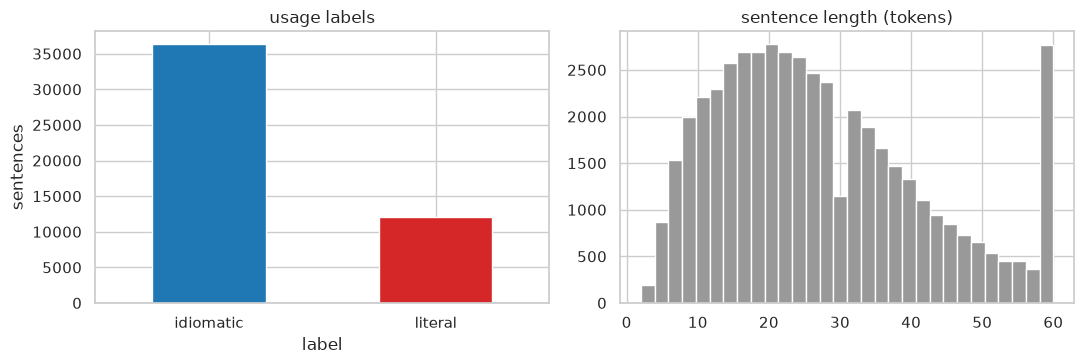

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
mag.label.value_counts().plot.bar(ax=axes[0], color=['#1f77b4', '#d62728']); axes[0].set_title('usage labels'); axes[0].set_ylabel('sentences')
mag.sentence.str.split().str.len().clip(upper=60).hist(bins=30, ax=axes[1], color='#999999'); axes[1].set_title('sentence length (tokens)')
plt.setp(axes[0].get_xticklabels(), rotation=0); plt.tight_layout(); plt.show()

**Figure 1: MAGPIE corpus analysis. Idiomatic uses outnumber literal ones three to one, and sentences are typically 15 to 30 tokens long.**

## 2. Step A: detector on real sentences

{'train': 38716, 'test': 4840, 'majority_acc': 0.746, 'acc': 0.862, 'macro_f1': 0.827, 'per_class': {'idiomatic': {'precision': 0.929, 'recall': 0.883, 'f1': 0.905}, 'literal': {'precision': 0.7, 'recall': 0.803, 'f1': 0.748}}}


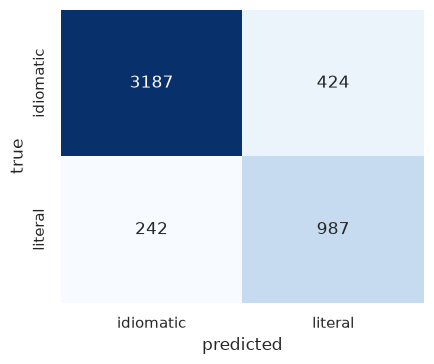

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, precision_recall_fscore_support

train = mag[mag.split == 'training']; test = mag[mag.split == 'test']
det = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=2),
                    LogisticRegression(max_iter=3000, class_weight='balanced'))
det.fit(train.sentence, train.label)
pred = det.predict(test.sentence)
p, r, f, _ = precision_recall_fscore_support(test.label, pred, labels=['idiomatic', 'literal'])
metrics['magpie'] = {'train': int(len(train)), 'test': int(len(test)),
                     'majority_acc': round(float(test.label.value_counts(normalize=True).iloc[0]), 3),
                     'acc': round(float(accuracy_score(test.label, pred)), 3),
                     'macro_f1': round(float(f1_score(test.label, pred, average='macro')), 3),
                     'per_class': {c: {'precision': round(float(p[i]), 3), 'recall': round(float(r[i]), 3), 'f1': round(float(f[i]), 3)} for i, c in enumerate(['idiomatic', 'literal'])}}
print(metrics['magpie'])
cm = confusion_matrix(test.label, pred, labels=['idiomatic', 'literal'])
fig, ax = plt.subplots(figsize=(4.5, 3.8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, xticklabels=['idiomatic', 'literal'], yticklabels=['idiomatic', 'literal'], ax=ax)
ax.set_xlabel('predicted'); ax.set_ylabel('true'); plt.tight_layout(); plt.show()

**Figure 2: Confusion matrix on the MAGPIE test split (4,840 real sentences).**

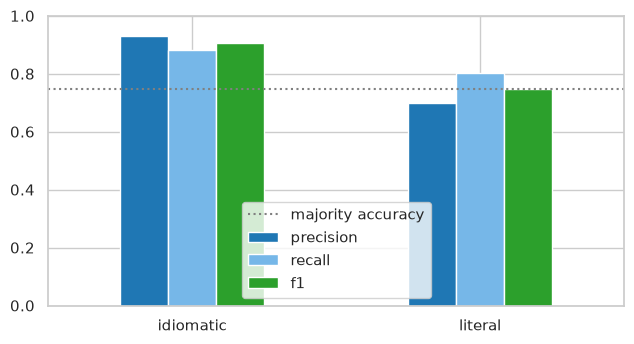

In [5]:
pc = pd.DataFrame(metrics['magpie']['per_class']).T
fig, ax = plt.subplots(figsize=(6.5, 3.6))
pc.plot.bar(ax=ax, color=['#1f77b4', '#76b7e8', '#2ca02c']); ax.set_ylim(0, 1); plt.xticks(rotation=0)
ax.axhline(metrics['magpie']['majority_acc'], color='grey', ls=':', label='majority accuracy'); ax.legend()
plt.tight_layout(); plt.show()

**Figure 3: Precision, recall and F1 per class on MAGPIE; the dotted line is the majority-class accuracy.**

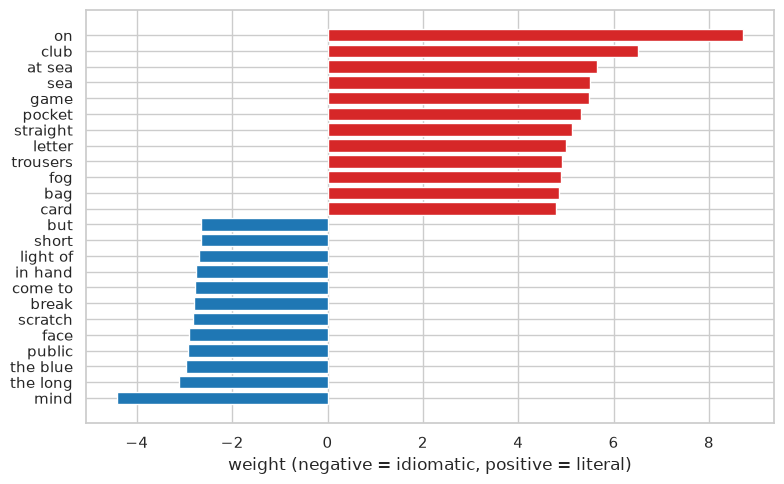

In [6]:
vec = det.named_steps['tfidfvectorizer']; clf = det.named_steps['logisticregression']
names = np.array(vec.get_feature_names_out()); w = clf.coef_[0]
top = np.concatenate([np.argsort(w)[:12], np.argsort(w)[-12:]])
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(names[top], w[top], color=['#1f77b4' if x < 0 else '#d62728' for x in w[top]])
ax.set_xlabel(f'weight (negative = {clf.classes_[0]}, positive = {clf.classes_[1]})'); plt.tight_layout(); plt.show()

**Figure 4: The strongest features for each class in the MAGPIE detector.**

## 3. Step B: the recipe applied to each language's proverbs

Positives: the corpus proverbs (literal translations) in six carrier sentences. Negatives: real literal MAGPIE sentences in the same carriers, so the templates cancel out. Register differs between 1890s book English and modern BNC English, which makes this easier than real detection; Step A is the honest number.

Marathi {'n': 2180, 'acc': 0.943, 'macro_f1': 0.943}


Hindi {'n': 1376, 'acc': 0.933, 'macro_f1': 0.933}


Assamese {'n': 412, 'acc': 0.913, 'macro_f1': 0.913}


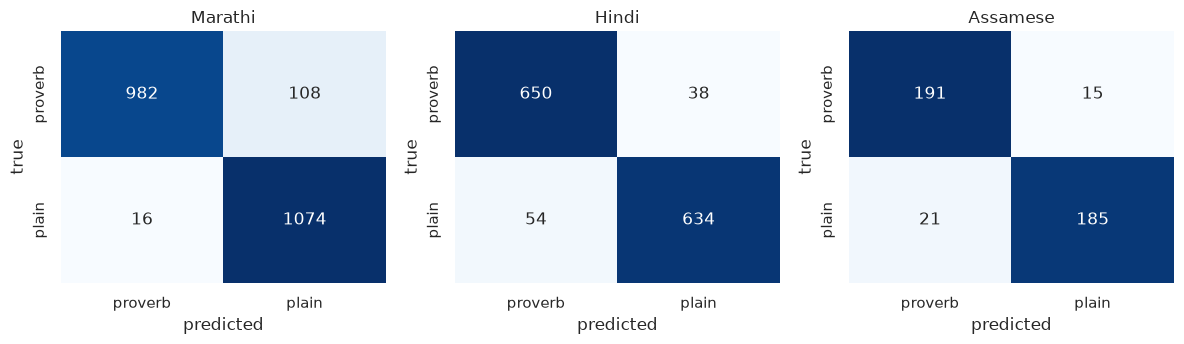

In [7]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
templates = ['My grandmother used to say that {}', 'As the saying goes, {}', 'He looked at me and said: {}',
             'In the end, {}', 'She reminded everyone that {}', 'It is well known that {}']
def clean(s):
    s = re.sub(r'\s+', ' ', str(s)).strip().rstrip('.')
    return s[0].lower() + s[1:] if s else s
lit = mag[mag.label == 'literal'].sentence
lit = lit[lit.str.split().str.len().between(5, 25)]
cv = StratifiedKFold(5, shuffle=True, random_state=42)
cms = {}
for l, L in LANGS:
    pos = [t.format(clean(p)) for p in corpora[l].literal_en for t in rng.choice(templates, 2, replace=False)]
    neg = [t.format(clean(s)) for s in rng.choice(lit.values, len(pos) // 2, replace=False) for t in rng.choice(templates, 2, replace=False)]
    X = pd.Series(pos + neg); y = pd.Series(['proverb'] * len(pos) + ['plain'] * len(neg))
    d2 = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=2), LogisticRegression(max_iter=3000, class_weight='balanced'))
    pr = cross_val_predict(d2, X, y, cv=cv)
    metrics[f'step_b_{l}'] = {'n': int(len(X)), 'acc': round(float(accuracy_score(y, pr)), 3), 'macro_f1': round(float(f1_score(y, pr, average='macro')), 3)}
    cms[L] = confusion_matrix(y, pr, labels=['proverb', 'plain'])
    print(L, metrics[f'step_b_{l}'])
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (L, cm) in zip(axes, cms.items()):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, xticklabels=['proverb', 'plain'], yticklabels=['proverb', 'plain'], ax=ax); ax.set_title(L); ax.set_xlabel('predicted'); ax.set_ylabel('true')
plt.tight_layout(); plt.show()

**Figure 5: Step B confusion matrices for Marathi, Hindi and Assamese proverbs in carrier sentences (5-fold cross-validation).**

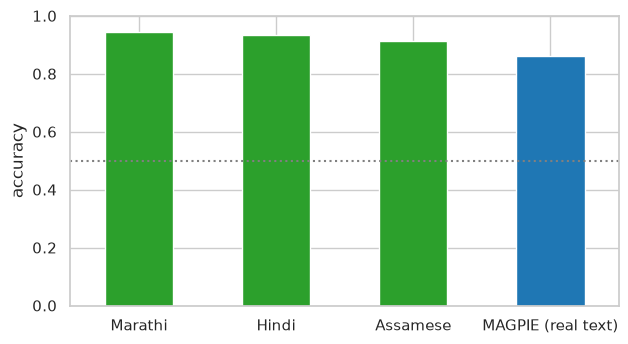

In [8]:
acc = pd.Series({L: metrics[f'step_b_{l}']['acc'] for l, L in LANGS}); acc['MAGPIE (real text)'] = metrics['magpie']['acc']
fig, ax = plt.subplots(figsize=(6.5, 3.6))
acc.plot.bar(ax=ax, color=['#2ca02c'] * 3 + ['#1f77b4']); ax.set_ylim(0, 1); ax.set_ylabel('accuracy'); plt.xticks(rotation=0)
ax.axhline(0.5, color='grey', ls=':'); plt.tight_layout(); plt.show()

**Figure 6: Detection accuracy for the three languages (Step B) next to the real-text result (Step A); dotted line is chance for Step B.**

## 4. The interface

`is_figurative()` is what a chatbot calls on a sentence.

In [9]:
def is_figurative(sentence):
    proba = det.predict_proba([sentence])[0]
    return dict(zip(det.classes_, np.round(proba, 3)))
print(is_figurative('After the merger the two teams were finally singing from the same hymn sheet.'))
print(is_figurative('The choir was singing from the same hymn sheet that the vicar had printed.'))

{'idiomatic': np.float64(0.671), 'literal': np.float64(0.329)}
{'idiomatic': np.float64(0.617), 'literal': np.float64(0.383)}


In [10]:
json.dump(metrics, open('report/PanelB_16_CCA3_v2_idiom_detection_metrics.json', 'w'), indent=1)
print(json.dumps(metrics, indent=1)[:2000])

{
 "magpie_counts": {
  "idiomatic": 36328,
  "literal": 12067
 },
 "magpie": {
  "train": 38716,
  "test": 4840,
  "majority_acc": 0.746,
  "acc": 0.862,
  "macro_f1": 0.827,
  "per_class": {
   "idiomatic": {
    "precision": 0.929,
    "recall": 0.883,
    "f1": 0.905
   },
   "literal": {
    "precision": 0.7,
    "recall": 0.803,
    "f1": 0.748
   }
  }
 },
 "step_b_marathi": {
  "n": 2180,
  "acc": 0.943,
  "macro_f1": 0.943
 },
 "step_b_hindi": {
  "n": 1376,
  "acc": 0.933,
  "macro_f1": 0.933
 },
 "step_b_assamese": {
  "n": 412,
  "acc": 0.913,
  "macro_f1": 0.913
 }
}


## Summary

On real text the detector separates idiomatic from literal usage well above the majority baseline, and the per-class figures show where it fails (literal uses are the minority and are the ones misread). The recipe transfers to all three proverb corpora in carrier sentences, with the register confound stated. `is_figurative()` is the detection back end for the team chatbot.

**References**
- Haagsma, H., Bos, J., & Nissim, M. (2020). MAGPIE: A large corpus of potentially idiomatic expressions. *Proceedings of LREC 2020*, 279-287.
- Tan, M., & Jiang, J. (2021). Does BERT understand idioms? A probing-based empirical study of BERT encodings of idioms. *Proceedings of RANLP 2021*, 1397-1407.